# Task 2 — Hands-On Data Lab Implementation
**YuvaIntern · Data Analyst Internship**
**Intern:** [Your Name]

**Objectives**
1. Set up a data science environment with Python, Jupyter and the required libraries.
2. Complete practical exercises in data manipulation, visualisation and basic analysis.

**Dataset:** Wine recognition dataset (UCI Machine Learning Repository) — chemical analysis of 178 wines grown in the same region of Italy by three different cultivators.

## Part A — Environment Setup

Steps followed to build the lab (Windows / macOS / Linux):

```bash
# 1. Install Python 3.11+ from python.org (tick "Add Python to PATH" on Windows)
python --version

# 2. Create and activate an isolated virtual environment
python -m venv dslab
dslab\Scripts\activate          # Windows
source dslab/bin/activate        # macOS / Linux

# 3. Install the libraries
pip install numpy pandas matplotlib seaborn scipy scikit-learn openpyxl jupyter

# 4. Save exact versions so anyone can rebuild the same lab
pip freeze > requirements.txt

# 5. Launch Jupyter
jupyter notebook
```
The cell below verifies that every library imports correctly and prints its version.

In [1]:
import sys, platform
from importlib.metadata import version

libs = ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "scikit-learn", "openpyxl"]
print(f"Python {sys.version.split()[0]} on {platform.system()}")
for lib in libs:
    print(f"  {lib:13} {version(lib)}")

Python 3.13.18 on Linux
  numpy         2.5.3
  pandas        3.0.5
  matplotlib    3.11.2
  seaborn       0.13.2
  scipy         1.18.1
  scikit-learn  1.9.1
  openpyxl      3.1.5


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_wine

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
print("Environment ready")

Environment ready


## Part B — Load and inspect the data

In [3]:
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map({0: "Cultivar A", 1: "Cultivar B", 2: "Cultivar C"})
df = df.drop(columns="target")
df = df.rename(columns={"od280/od315_of_diluted_wines": "od280_od315",
                        "nonflavanoid_phenols": "nonflav_phenols"})
df.to_csv("data/wine.csv", index=False)       # keep a local copy of the raw data

print("Rows, columns:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
display(df.head())

Rows, columns: (178, 14)
Missing values: 0 | Duplicates: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflav_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,Cultivar A
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,Cultivar A
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,Cultivar A
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,Cultivar A
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,Cultivar A


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   alcohol            178 non-null    float64
 1   malic_acid         178 non-null    float64
 2   ash                178 non-null    float64
 3   alcalinity_of_ash  178 non-null    float64
 4   magnesium          178 non-null    float64
 5   total_phenols      178 non-null    float64
 6   flavanoids         178 non-null    float64
 7   nonflav_phenols    178 non-null    float64
 8   proanthocyanins    178 non-null    float64
 9   color_intensity    178 non-null    float64
 10  hue                178 non-null    float64
 11  od280_od315        178 non-null    float64
 12  proline            178 non-null    float64
 13  cultivar           178 non-null    str    
dtypes: float64(13), str(1)
memory usage: 19.6 KB


## Part C — Data manipulation exercises
**C1. Select columns and filter rows** — wines with alcohol above 14% and low colour intensity.

In [5]:
strong = df.loc[(df.alcohol > 14) & (df.color_intensity < 6), ["alcohol", "color_intensity", "cultivar"]]
print(len(strong), "wines match")
display(strong.sort_values("alcohol", ascending=False))

12 wines match


,alcohol,color_intensity,cultivar
8,14.83,5.20,Cultivar A
13,14.75,5.40,Cultivar A
6,14.39,5.25,Cultivar A
46,14.38,4.90,Cultivar A
0,14.23,5.64,Cultivar A
39,14.22,5.10,Cultivar A
45,14.21,5.24,Cultivar A
11,14.12,5.00,Cultivar A
10,14.10,5.75,Cultivar A
7,14.06,5.05,Cultivar A


**C2. Sort and rank** — top 5 wines by proline (an amino acid linked to quality).

In [6]:
df["proline_rank"] = df["proline"].rank(ascending=False).astype(int)
display(df.nlargest(5, "proline")[["proline", "proline_rank", "alcohol", "cultivar"]])

,proline,proline_rank,alcohol,cultivar
18,1680.0,1,14.19,Cultivar A
14,1547.0,2,14.38,Cultivar A
31,1515.0,3,13.58,Cultivar A
10,1510.0,4,14.10,Cultivar A
3,1480.0,5,14.37,Cultivar A


**C3. Create new columns** — a phenol ratio and an alcohol band using `pd.cut`.

In [7]:
df["flav_ratio"] = (df["flavanoids"] / df["total_phenols"]).round(3)
df["alcohol_band"] = pd.cut(df["alcohol"], bins=[0, 12.5, 13.5, 15],
                            labels=["Light (<12.5%)", "Medium (12.5-13.5%)", "Strong (>13.5%)"])
display(df[["flavanoids", "total_phenols", "flav_ratio", "alcohol", "alcohol_band"]].head())

,flavanoids,total_phenols,flav_ratio,alcohol,alcohol_band
0,3.06,2.80,1.093,14.23,Strong (>13.5%)
1,2.76,2.65,1.042,13.20,Medium (12.5-13.5%)
2,3.24,2.80,1.157,13.16,Medium (12.5-13.5%)
3,3.49,3.85,0.906,14.37,Strong (>13.5%)
4,2.69,2.80,0.961,13.24,Medium (12.5-13.5%)


**C4. Group and aggregate** — average profile of each cultivar.

In [8]:
profile = df.groupby("cultivar").agg(
    wines=("alcohol", "size"),
    alcohol_mean=("alcohol", "mean"),
    flavanoids_mean=("flavanoids", "mean"),
    color_mean=("color_intensity", "mean"),
    proline_mean=("proline", "mean"),
).round(2)
display(profile)

,wines,alcohol_mean,flavanoids_mean,color_mean,proline_mean
cultivar,,,,,
Cultivar A,59,13.74,2.98,5.53,1115.71
Cultivar B,71,12.28,2.08,3.09,519.51
Cultivar C,48,13.15,0.78,7.40,629.90


**C5. Pivot table and cross-tab** — how many wines of each cultivar fall in each alcohol band.

In [9]:
display(pd.crosstab(df["cultivar"], df["alcohol_band"], margins=True, margins_name="Total"))
display(df.pivot_table(index="alcohol_band", columns="cultivar", values="color_intensity",
                       aggfunc="mean", observed=True).round(2))

alcohol_band,Light (<12.5%),Medium (12.5-13.5%),Strong (>13.5%),Total
cultivar,,,,
Cultivar A,0,18,41,59
Cultivar B,52,17,2,71
Cultivar C,5,31,12,48
Total,57,66,55,178


cultivar,Cultivar A,Cultivar B,Cultivar C
alcohol_band,,,
Light (<12.5%),NaN,2.93,6.54
Medium (12.5-13.5%),4.62,3.50,7.40
Strong (>13.5%),5.93,3.59,7.75


**C6. Merge with a lookup table** — add descriptive information about each cultivar.

In [10]:
lookup = pd.DataFrame({
    "cultivar": ["Cultivar A", "Cultivar B", "Cultivar C"],
    "style": ["Full-bodied, high proline", "Light, low colour", "Deep colour, low flavanoids"],
    "code": ["A", "B", "C"],
})
merged = df.merge(lookup, on="cultivar", how="left")
print("Shape after merge:", merged.shape)
display(merged[["cultivar", "code", "style", "alcohol"]].drop_duplicates("cultivar"))

Shape after merge: (178, 19)


,cultivar,code,style,alcohol
0,Cultivar A,A,"Full-bodied, high proline",14.23
59,Cultivar B,B,"Light, low colour",12.37
130,Cultivar C,C,"Deep colour, low flavanoids",12.86


**C7. Reshape (wide → long) with `melt`, and apply a custom function.**

In [11]:
long = df[["cultivar", "alcohol", "ash", "hue"]].melt(id_vars="cultivar", var_name="measure", value_name="value")
print("Wide shape:", df[["cultivar", "alcohol", "ash", "hue"]].shape, "-> long shape:", long.shape)
display(long.head())

def quality_flag(row):
    return "Premium" if row["proline"] > 1000 and row["alcohol"] > 13.5 else "Standard"
df["segment"] = df.apply(quality_flag, axis=1)
print(df["segment"].value_counts())

Wide shape: (178, 4) -> long shape: (534, 3)


,cultivar,measure,value
0,Cultivar A,alcohol,14.23
1,Cultivar A,alcohol,13.20
2,Cultivar A,alcohol,13.16
3,Cultivar A,alcohol,14.37
4,Cultivar A,alcohol,13.24


segment
Standard    145
Premium      33
Name: count, dtype: int64


**C8. Handling missing values** — the dataset is complete, so 5% of `magnesium` values are removed on purpose to practise imputation.

In [12]:
practice = df.copy()
rng = np.random.default_rng(7)
idx = rng.choice(practice.index, size=9, replace=False)
practice.loc[idx, "magnesium"] = np.nan
print("Missing magnesium after removal:", practice.magnesium.isna().sum())

# impute with the median of each cultivar (better than one overall median)
practice["magnesium"] = practice.groupby("cultivar")["magnesium"].transform(lambda s: s.fillna(s.median()))
error = (practice.loc[idx, "magnesium"] - df.loc[idx, "magnesium"]).abs().mean()
print("Missing after imputation:", practice.magnesium.isna().sum(), f"| mean absolute error = {error:.1f} mg")

Missing magnesium after removal: 9
Missing after imputation: 0 | mean absolute error = 11.6 mg


## Part D — Visualisation exercises

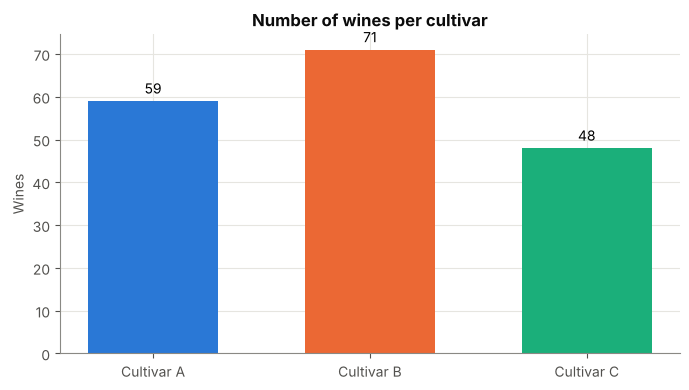

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df["cultivar"].value_counts().sort_index()
bars = ax.bar(counts.index, counts.values, color=COLORS, width=0.6)
ax.bar_label(bars, padding=3)
ax.set_title("Number of wines per cultivar")
ax.set_ylabel("Wines")
plt.tight_layout()
plt.savefig("figures/01_bar_cultivar_counts.png", dpi=150, bbox_inches="tight")

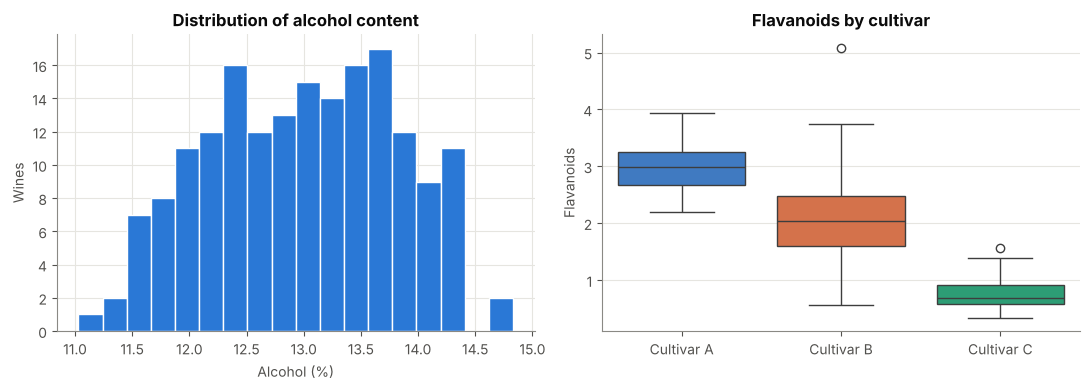

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["alcohol"], bins=18, color="#2a78d6", edgecolor="white")
axes[0].set_title("Distribution of alcohol content")
axes[0].set_xlabel("Alcohol (%)"); axes[0].set_ylabel("Wines")
sns.boxplot(data=df, x="cultivar", y="flavanoids", hue="cultivar", palette=COLORS, ax=axes[1], legend=False)
axes[1].set_title("Flavanoids by cultivar")
axes[1].set_xlabel(""); axes[1].set_ylabel("Flavanoids")
plt.tight_layout()
plt.savefig("figures/02_hist_box.png", dpi=150, bbox_inches="tight")

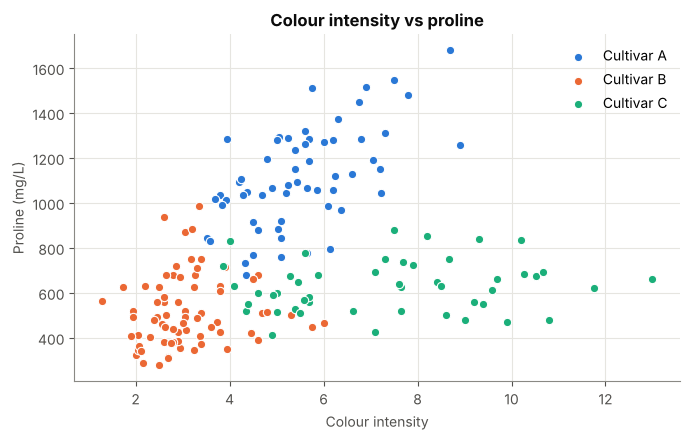

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, c in zip(sorted(df.cultivar.unique()), COLORS):
    part = df[df.cultivar == name]
    ax.scatter(part.color_intensity, part.proline, s=36, color=c, label=name, edgecolor="white", linewidth=0.8)
ax.set_xlabel("Colour intensity"); ax.set_ylabel("Proline (mg/L)")
ax.set_title("Colour intensity vs proline")
ax.legend()
plt.tight_layout()
plt.savefig("figures/03_scatter_color_proline.png", dpi=150, bbox_inches="tight")

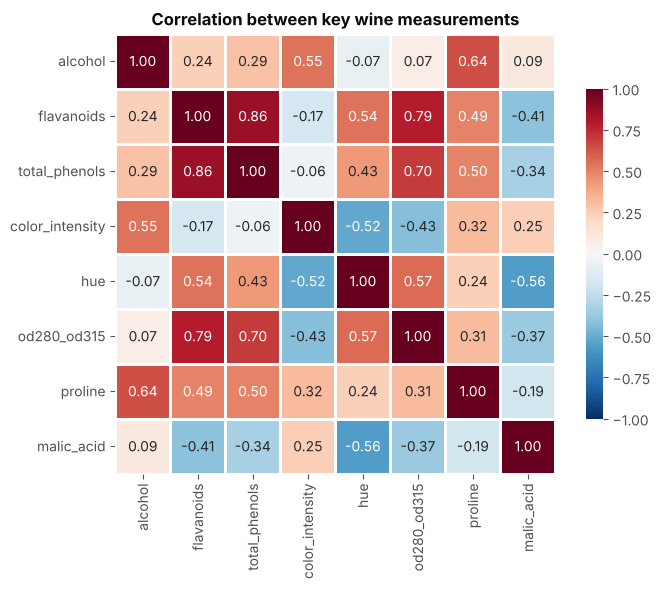

In [16]:
cols = ["alcohol", "flavanoids", "total_phenols", "color_intensity", "hue", "od280_od315", "proline", "malic_acid"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=1, linecolor="white", cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation between key wine measurements")
plt.tight_layout()
plt.savefig("figures/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")

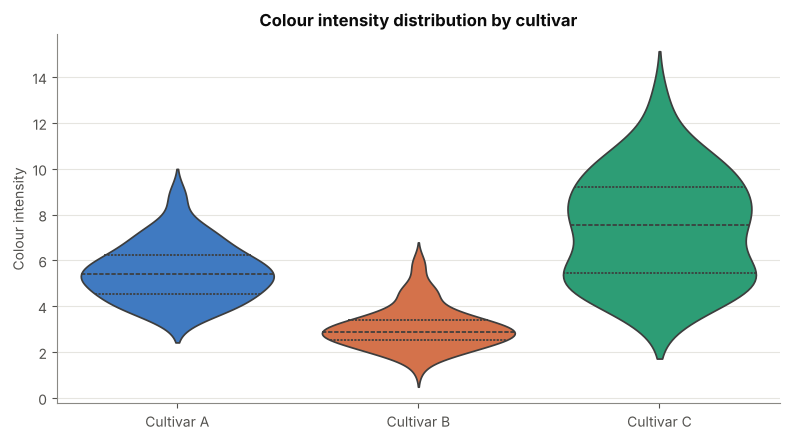

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.violinplot(data=df, x="cultivar", y="color_intensity", hue="cultivar", palette=COLORS,
               inner="quartile", ax=ax, legend=False)
ax.set_title("Colour intensity distribution by cultivar")
ax.set_xlabel(""); ax.set_ylabel("Colour intensity")
plt.tight_layout()
plt.savefig("figures/05_violin_color.png", dpi=150, bbox_inches="tight")

## Part E — Basic analysis
**E1. Which measurements separate the cultivars most?** One-way ANOVA F-test for every feature (higher F = stronger difference between groups).

In [18]:
features = [c for c in wine.feature_names]
features = [ {"od280/od315_of_diluted_wines": "od280_od315", "nonflavanoid_phenols": "nonflav_phenols"}.get(c, c) for c in features]
rows = []
for f in features:
    groups = [g[f].values for _, g in df.groupby("cultivar")]
    F, p = stats.f_oneway(*groups)
    rows.append((f, F, p))
anova = pd.DataFrame(rows, columns=["feature", "F_statistic", "p_value"]).sort_values("F_statistic", ascending=False)
anova["significant"] = anova.p_value < 0.05
display(anova.round(4).reset_index(drop=True))

,feature,F_statistic,p_value,significant
0,flavanoids,233.9259,0.0,True
1,proline,207.9204,0.0,True
2,od280_od315,189.9723,0.0,True
3,alcohol,135.0776,0.0,True
4,color_intensity,120.6640,0.0,True
5,hue,101.3168,0.0,True
6,total_phenols,93.7330,0.0,True
7,malic_acid,36.9434,0.0,True
8,alcalinity_of_ash,35.7716,0.0,True
9,proanthocyanins,30.2714,0.0,True


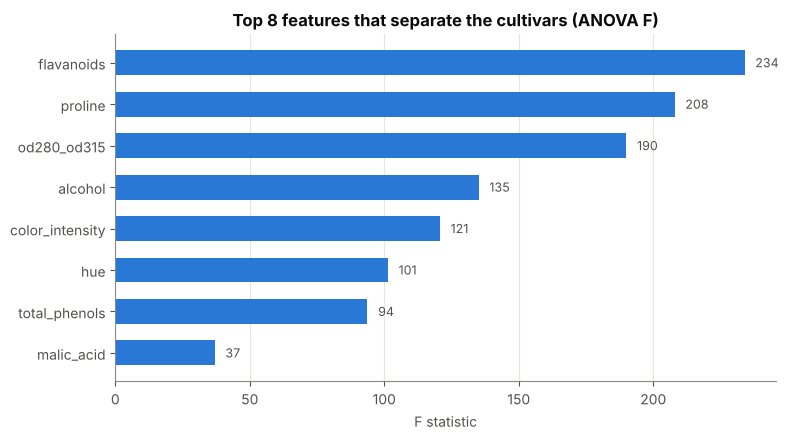

In [19]:
top = anova.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.feature, top.F_statistic, color="#2a78d6", height=0.6)
for y, v in enumerate(top.F_statistic):
    ax.text(v + 4, y, f"{v:.0f}", va="center", fontsize=9, color="#52514e")
ax.set_title("Top 8 features that separate the cultivars (ANOVA F)")
ax.set_xlabel("F statistic")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("figures/06_anova_top_features.png", dpi=150, bbox_inches="tight")

**E2. Is alcohol related to colour intensity?**

In [20]:
r, p = stats.pearsonr(df.alcohol, df.color_intensity)
print(f"Pearson r = {r:.3f}, p = {p:.2e}")
slope, intercept, r_lin, p_lin, se = stats.linregress(df.alcohol, df.color_intensity)
print(f"Each extra 1% alcohol adds about {slope:.2f} units of colour intensity (R^2 = {r_lin**2:.2f})")

Pearson r = 0.546, p = 3.06e-15
Each extra 1% alcohol adds about 1.56 units of colour intensity (R^2 = 0.30)


**E3. Save the cleaned and enriched dataset**

In [21]:
df.to_csv("data/wine_enriched.csv", index=False)
print("Saved data/wine_enriched.csv with", df.shape[1], "columns")

Saved data/wine_enriched.csv with 18 columns


## Summary
- A reproducible lab was built: virtual environment, pinned libraries (`requirements.txt`) and Jupyter.
- Eight manipulation exercises covered selecting, filtering, sorting, ranking, new columns, grouping, pivoting, merging, reshaping, `apply` and imputing missing values.
- Six charts (bar, histogram, box, scatter, heatmap, violin, horizontal bar) were produced.
- Flavanoids, proline and OD280/OD315 differ most between cultivars; all 13 measurements differ significantly.
- Alcohol and colour intensity are moderately positively related.